<div style="background:#101C35;padding:28px 32px;border-radius:12px;">
<h1 style="color:#FFFFFF;margin:0;">Supply Chain Performance Analytics and Delivery Efficiency Optimization</h1>
<p style="color:#B8C4DC;margin:8px 0 0 0;font-size:15px;">Jupyter Notebook version of the Streamlit project <b>"Supply Chain Intelligence"</b> &nbsp;|&nbsp; Python · Pandas · Plotly · Scikit-learn · Random Forest · XGBoost</p>
</div>

**Notebook contents**

1. Project Introduction
2. Dataset Description
3. Data Preprocessing
4. Executive Overview
5. Delivery Intelligence
6. Delivery Risk Analysis
7. Regional Analytics
8. Revenue Analytics
9. Product Analytics
10. Machine Learning: Random Forest
11. Machine Learning: XGBoost
12. Model Comparison
13. Feature Importance Analysis
14. Final Insights and Conclusion

# 1. Project Introduction

## 1.1 Abstract
This project analyses supply chain order data to understand **delivery performance** and to identify the factors associated with **delayed deliveries**. The original work was built as a six-page Streamlit dashboard (Executive Overview, Delivery Intelligence, Delivery Risk Analysis, Regional Analytics, Revenue Analytics and Product Analytics). This notebook reproduces that dashboard analysis with the data available in `ml_training_data.csv` and adds two supervised machine-learning models, **Random Forest** and **XGBoost**, that classify whether an order is delayed (`Is_Delayed`). The models are evaluated on the same stratified train-test split and compared using Accuracy, Precision, Recall, F1-score and ROC-AUC.

## 1.2 Introduction
Late deliveries reduce customer satisfaction and increase operating cost. Logistics teams therefore monitor delivery performance by shipping mode, region, market and product category. The Streamlit dashboard gave decision-makers an interactive view of these indicators; this notebook documents the same analysis step by step so that it can be reviewed, reproduced and presented.

## 1.3 Problem Statement
Many orders are not delivered on time, but it is not obvious *where* delays concentrate (which shipping modes, regions, markets or products) or *which order characteristics* are associated with them. The project asks: **how is delivery performance distributed across the supply chain, and can order attributes be used to classify delayed orders?**

## 1.4 Project Objectives
- Prepare and validate the supply chain order dataset.
- Reproduce the dashboard KPIs and charts wherever the available columns allow.
- Analyse delivery risk by shipping mode, region, market and product category.
- Train and evaluate Random Forest and XGBoost classifiers for `Is_Delayed`.
- Compare the models fairly and examine which features they rely on.
- Document limitations and possible future improvements.

## 1.5 Scope of the Project
The analysis uses **only** the 23 columns in `ml_training_data.csv` (65,752 orders). It covers descriptive analytics (dashboard pages) and predictive modelling (classification of `Is_Delayed`). Information that is not in this file, such as actual delivery days, delay days, exact order dates, inventory or supplier data, is **not** estimated or invented. Where a dashboard chart needs such a field, the notebook says so and offers a clearly labelled alternative.

## 1.6 Technologies Used
| Area | Tools |
|---|---|
| Language | Python 3 |
| Data handling | Pandas, NumPy |
| Visualisation | Plotly Express, Plotly Graph Objects (interactive); Matplotlib and Seaborn (correlation check) |
| Machine learning | Scikit-learn (pipelines, Random Forest, metrics), XGBoost |
| Original dashboard | Streamlit |

In [1]:
# Install only what is missing (Google Colab already ships with these packages)
import importlib.util, subprocess, sys

for pkg in ["xgboost", "plotly"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

# Core libraries
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display, HTML, Markdown

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
RANDOM_STATE = 42

# Colour palette taken from the Streamlit dashboard
BLUE, GREEN, RED, AMBER, NAVY = "#3979D6", "#24A47A", "#E45C68", "#F0A64A", "#17233B"
STATUS_COLORS = {"Not Delayed": GREEN, "Delayed": RED, "Low Risk": GREEN, "High Risk": RED}


def chart_style(fig, height=380):
    # Same look as the dashboard's chart_style(): white template, clean grid, readable fonts.
    fig.update_layout(
        height=height, template="plotly_white",
        margin=dict(l=40, r=30, t=65, b=50),
        font=dict(family="Inter, Arial, sans-serif", size=12, color="#344054"),
        paper_bgcolor="#FFFFFF", plot_bgcolor="#FFFFFF",
        title=dict(x=0.01, font=dict(size=16, color=NAVY)),
        legend=dict(bgcolor="rgba(255,255,255,0)"),
    )
    fig.update_xaxes(showgrid=False, zeroline=False)
    fig.update_yaxes(gridcolor="#E9EDF4", zeroline=False)
    return fig


def show(fig, height=380):
    chart_style(fig, height).show()


def kpi_cards(cards):
    # Render KPI cards (like the dashboard's metric_card). cards = [(label, value, note, icon), ...]
    html = '<div style="display:flex;gap:14px;flex-wrap:wrap;font-family:Inter,Arial,sans-serif;margin:8px 0 14px 0;">'
    for label, value, note, icon in cards:
        html += f'''
        <div style="flex:1;min-width:190px;background:#FFFFFF;border:1px solid #E8ECF3;border-radius:12px;
                    padding:16px 18px;box-shadow:0 2px 8px rgba(20,40,80,0.06);">
            <div style="display:flex;justify-content:space-between;">
                <span style="color:#7C879B;font-size:12px;font-weight:600;letter-spacing:.5px;text-transform:uppercase;">{label}</span>
                <span style="font-size:20px;">{icon}</span>
            </div>
            <div style="color:#17233B;font-size:26px;font-weight:800;margin-top:10px;">{value}</div>
            <div style="color:#8792A5;font-size:11px;margin-top:4px;">{note}</div>
        </div>'''
    display(HTML(html + "</div>"))


print("Libraries loaded successfully.")

Libraries loaded successfully.


# 2. Dataset Description

The dataset `ml_training_data.csv` is the machine-learning dataset of the project. The code below looks for the file in the current folder, in a `data/` folder and in `/content` (Google Colab). If it is not found in Colab, an upload dialog opens.

In [2]:
DATA_FILE = "ml_training_data.csv"
search_paths = [Path(DATA_FILE), Path("data") / DATA_FILE, Path("/content") / DATA_FILE]
data_path = next((p for p in search_paths if p.exists()), None)

if data_path is None:
    try:
        from google.colab import files          # works only inside Google Colab
        print(f"Please upload {DATA_FILE}")
        files.upload()
        data_path = Path(DATA_FILE)
    except ImportError:
        raise FileNotFoundError(f"{DATA_FILE} not found. Place it next to this notebook.")

raw_df = pd.read_csv(data_path)
print(f"Loaded: {data_path}")
print(f"Dataset shape: {raw_df.shape[0]:,} rows x {raw_df.shape[1]} columns")

Loaded: ml_training_data.csv
Dataset shape: 65,752 rows x 23 columns


In [3]:
print("Column names:")
for i, col in enumerate(raw_df.columns, 1):
    print(f"{i:>2}. {col}")

print("\nFirst five records:")
display(raw_df.head())

Column names:
 1. Order Id
 2. Type
 3. Days for shipment (scheduled)
 4. Benefit per order
 5. Sales per customer
 6. Category Id
 7. Category Name
 8. Customer Segment
 9. Customer State
10. Customer Country
11. Market
12. Order City
13. Order Country
14. Order Region
15. Order Item Discount
16. Order Item Discount Rate
17. Order Item Quantity
18. Product Price
19. Shipping Mode
20. Is_Delayed
21. Order Month
22. Order DayOfWeek
23. Order Year

First five records:


,Order Id,Type,Days for shipment (scheduled),Benefit per order,Sales per customer,Category Id,Category Name,Customer Segment,Customer State,Customer Country,Market,Order City,Order Country,Order Region,Order Item Discount,Order Item Discount Rate,Order Item Quantity,Product Price,Shipping Mode,Is_Delayed,Order Month,Order DayOfWeek,Order Year
0,1,CASH,4.00,88.79,239.98,43.00,Camping & Hiking,Consumer,NC,EE. UU.,LATAM,Mexico City,México,Central America,60.00,0.20,1,299.98,Standard Class,0,1,3,2015
1,2,PAYMENT,4.00,65.30,176.46,30.00,Water Sports,Consumer,IL,EE. UU.,LATAM,Dos Quebradas,Colombia,South America,16.87,0.10,7,126.66,Standard Class,0,1,3,2015
2,4,CASH,4.00,31.02,155.22,31.75,Accessories,Home Office,TX,EE. UU.,LATAM,Dos Quebradas,Colombia,South America,19.74,0.14,14,46.24,Standard Class,1,1,3,2015
3,5,DEBIT,4.00,78.02,197.41,33.40,Men's Footwear,Consumer,PR,Puerto Rico,LATAM,Dos Quebradas,Colombia,South America,28.56,0.14,10,167.98,Standard Class,1,1,3,2015
4,7,DEBIT,2.00,67.98,175.17,44.00,Camping & Hiking,Consumer,FL,EE. UU.,LATAM,São Paulo,Brasil,South America,18.13,0.07,7,171.99,Second Class,1,1,3,2015


In [4]:
quality = pd.DataFrame({
    "Data Type": raw_df.dtypes.astype(str),
    "Missing Values": raw_df.isna().sum(),
    "Unique Values": raw_df.nunique(),
})
display(quality)

print(f"Total missing values : {int(raw_df.isna().sum().sum()):,}")
print(f"Duplicate records    : {int(raw_df.duplicated().sum()):,}")
print(f"Duplicate Order Ids  : {int(raw_df['Order Id'].duplicated().sum()):,}  "
      f"(unique Order Ids = {raw_df['Order Id'].nunique():,})")

,Data Type,Missing Values,Unique Values
Order Id,int64,0,65752
Type,str,0,4
Days for shipment (scheduled),float64,0,4
Benefit per order,float64,0,55210
Sales per customer,float64,0,44489
Category Id,float64,0,402
Category Name,str,0,50
Customer Segment,str,0,3
Customer State,str,0,46
Customer Country,str,0,2


Total missing values : 0
Duplicate records    : 0
Duplicate Order Ids  : 0  (unique Order Ids = 65,752)


### 2.1 Feature Explanation

| Feature | Type | Meaning |
|---|---|---|
| `Order Id` | Identifier | Unique order number (used only for counting orders, never as a model feature) |
| `Type` | Categorical | Payment type (CASH, PAYMENT, DEBIT, TRANSFER) |
| `Days for shipment (scheduled)` | Numeric | Planned delivery duration in days |
| `Benefit per order` | Numeric | Profit/benefit of the order (can be negative) |
| `Sales per customer` | Numeric | Monetary sales value of the order record; the **only sales measure** in this file |
| `Category Id`, `Category Name` | Numeric / Categorical | Product category code and name |
| `Customer Segment` | Categorical | Consumer, Corporate or Home Office |
| `Customer State`, `Customer Country` | Categorical | Customer location |
| `Market`, `Order Region`, `Order Country`, `Order City` | Categorical | Order destination hierarchy |
| `Order Item Discount`, `Order Item Discount Rate` | Numeric | Discount amount and discount rate |
| `Order Item Quantity` | Numeric | Number of units in the order record |
| `Product Price` | Numeric | Product price |
| `Shipping Mode` | Categorical | Standard Class, Second Class, First Class, Same Day |
| `Is_Delayed` | Binary target | 1 = delayed order, 0 = not delayed (existing label in the dataset) |
| `Order Month`, `Order DayOfWeek`, `Order Year` | Numeric | Order timing information |

**Important observations about this file**
- The file has **one row per `Order Id`**. Some values (for example `Category Id`) contain decimals, which suggests that item-level values were averaged per order when the file was prepared. Therefore, totals computed here are **not identical** to the item-level totals of the original 180,519-row dashboard.
- The file contains **no exact order date, no actual shipping days, no delivery delay days and no `Sales` column**.

### 2.2 Streamlit Dashboard vs. Available Data

Every chart of `app.py` was checked against the available columns:

| Dashboard page | Original chart | Needs | Status in this notebook |
|---|---|---|---|
| Executive Overview | Monthly Sales Trend (area) | `Sales`, order date | Reproduced with `Sales per customer` and Order Year/Month (monthly granularity) |
| | Delivery Status Distribution (donut) | Delay days (On Time / Early / Delayed) | Reproduced as Delayed vs Not Delayed from `Is_Delayed` (Early / On Time cannot be separated) |
| | Shipping Mode Performance (bar of actual days) | `Days for shipping (real)` | **Not available**; alternative: delay rate by shipping mode |
| | Regional Sales Contribution (bar) | `Sales`, region | Reproduced with `Sales per customer` |
| Delivery Intelligence | Actual vs Scheduled Delivery (grouped bar) | `Days for shipping (real)` | **Not available**; alternative: Delayed vs Not Delayed orders by shipping mode |
| | Delivery Delay Distribution (histogram) | `Delivery Delay Days` | **Not available**; alternative: monthly delay-rate trend |
| | Shipping Mode Detailed Performance (table) | actual days, delay days | Reproduced with available columns |
| Delivery Risk Analysis | Risk distribution, risk by mode, risk by region | `Late_delivery_risk` | Reproduced using `Is_Delayed` |
| | Recorded risk vs actual outcome | `Delivery Delay Days` | **Not available**; alternative: profile of delayed vs non-delayed orders |
| Regional Analytics | Regional sales bar, delay bar, performance matrix, table | `Sales`, delay days | Reproduced; average delay days replaced by delay rate |
| Revenue Analytics | Monthly revenue, sales by market, market comparison | `Sales`, date | Reproduced with `Sales per customer` |
| Product Analytics | Top 15 categories, demand treemap, category table | `Sales`, quantity, price | Reproduced with `Sales per customer` |

# 3. Data Preprocessing

The aim is to keep every valid record and the original meaning of each column. The steps are:
1. Standardise text columns (remove extra spaces, e.g. `"South of  USA "` becomes `"South of USA"`).
2. Check missing values and duplicates.
3. Validate numerical columns.
4. Create the helper columns needed for the dashboard (delivery status, risk status, order period).
5. Define the features and target for machine learning.

In [5]:
df = raw_df.copy()

# 1) Standardise text columns (trailing / double spaces only; no label is changed otherwise)
text_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
for c in text_cols:
    df[c] = df[c].str.strip().str.replace(r"\s+", " ", regex=True)

# 2) Missing values and duplicates
print(f"Missing values after cleaning : {int(df.isna().sum().sum())}")
print(f"Duplicate rows                : {int(df.duplicated().sum())}")
print(f"Order Id is unique            : {df['Order Id'].is_unique}")

# 3) Validate numerical columns
numeric_cols = df.select_dtypes(include="number").columns.tolist()
for c in numeric_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

validation = pd.Series({
    "Target not in {0,1}": (~df["Is_Delayed"].isin([0, 1])).sum(),
    "Sales per customer <= 0": (df["Sales per customer"] <= 0).sum(),
    "Product Price <= 0": (df["Product Price"] <= 0).sum(),
    "Order Item Quantity <= 0": (df["Order Item Quantity"] <= 0).sum(),
    "Discount rate outside [0, 1]": (~df["Order Item Discount Rate"].between(0, 1)).sum(),
    "Order Month outside 1-12": (~df["Order Month"].between(1, 12)).sum(),
    "Negative Benefit per order (valid: loss-making orders)": (df["Benefit per order"] < 0).sum(),
}, name="Records")
display(validation.to_frame())

Missing values after cleaning : 0
Duplicate rows                : 0
Order Id is unique            : True


,Records
"Target not in {0,1}",0
Sales per customer <= 0,0
Product Price <= 0,0
Order Item Quantity <= 0,0
"Discount rate outside [0, 1]",0
Order Month outside 1-12,0
Negative Benefit per order (valid: loss-making orders),13909


In [6]:
# 4) Helper columns used by the dashboard analysis (original columns are not modified)
df["Delivery Status"] = np.where(df["Is_Delayed"] == 1, "Delayed", "Not Delayed")
df["Risk Status"] = df["Is_Delayed"].map({0: "Low Risk", 1: "High Risk"})
df["Order Period"] = pd.to_datetime(dict(year=df["Order Year"], month=df["Order Month"], day=1))

SALES = "Sales per customer"          # the only sales measure available in this dataset

print("Order period covered:", df["Order Period"].min().strftime("%b %Y"), "to", df["Order Period"].max().strftime("%b %Y"))
print("Orders per year:")
display(df["Order Year"].value_counts().sort_index().rename("Orders").to_frame())

Order period covered: Jan 2015 to Jan 2018
Orders per year:


,Orders
Order Year,
2015,20904
2016,20859
2017,21866
2018,2123


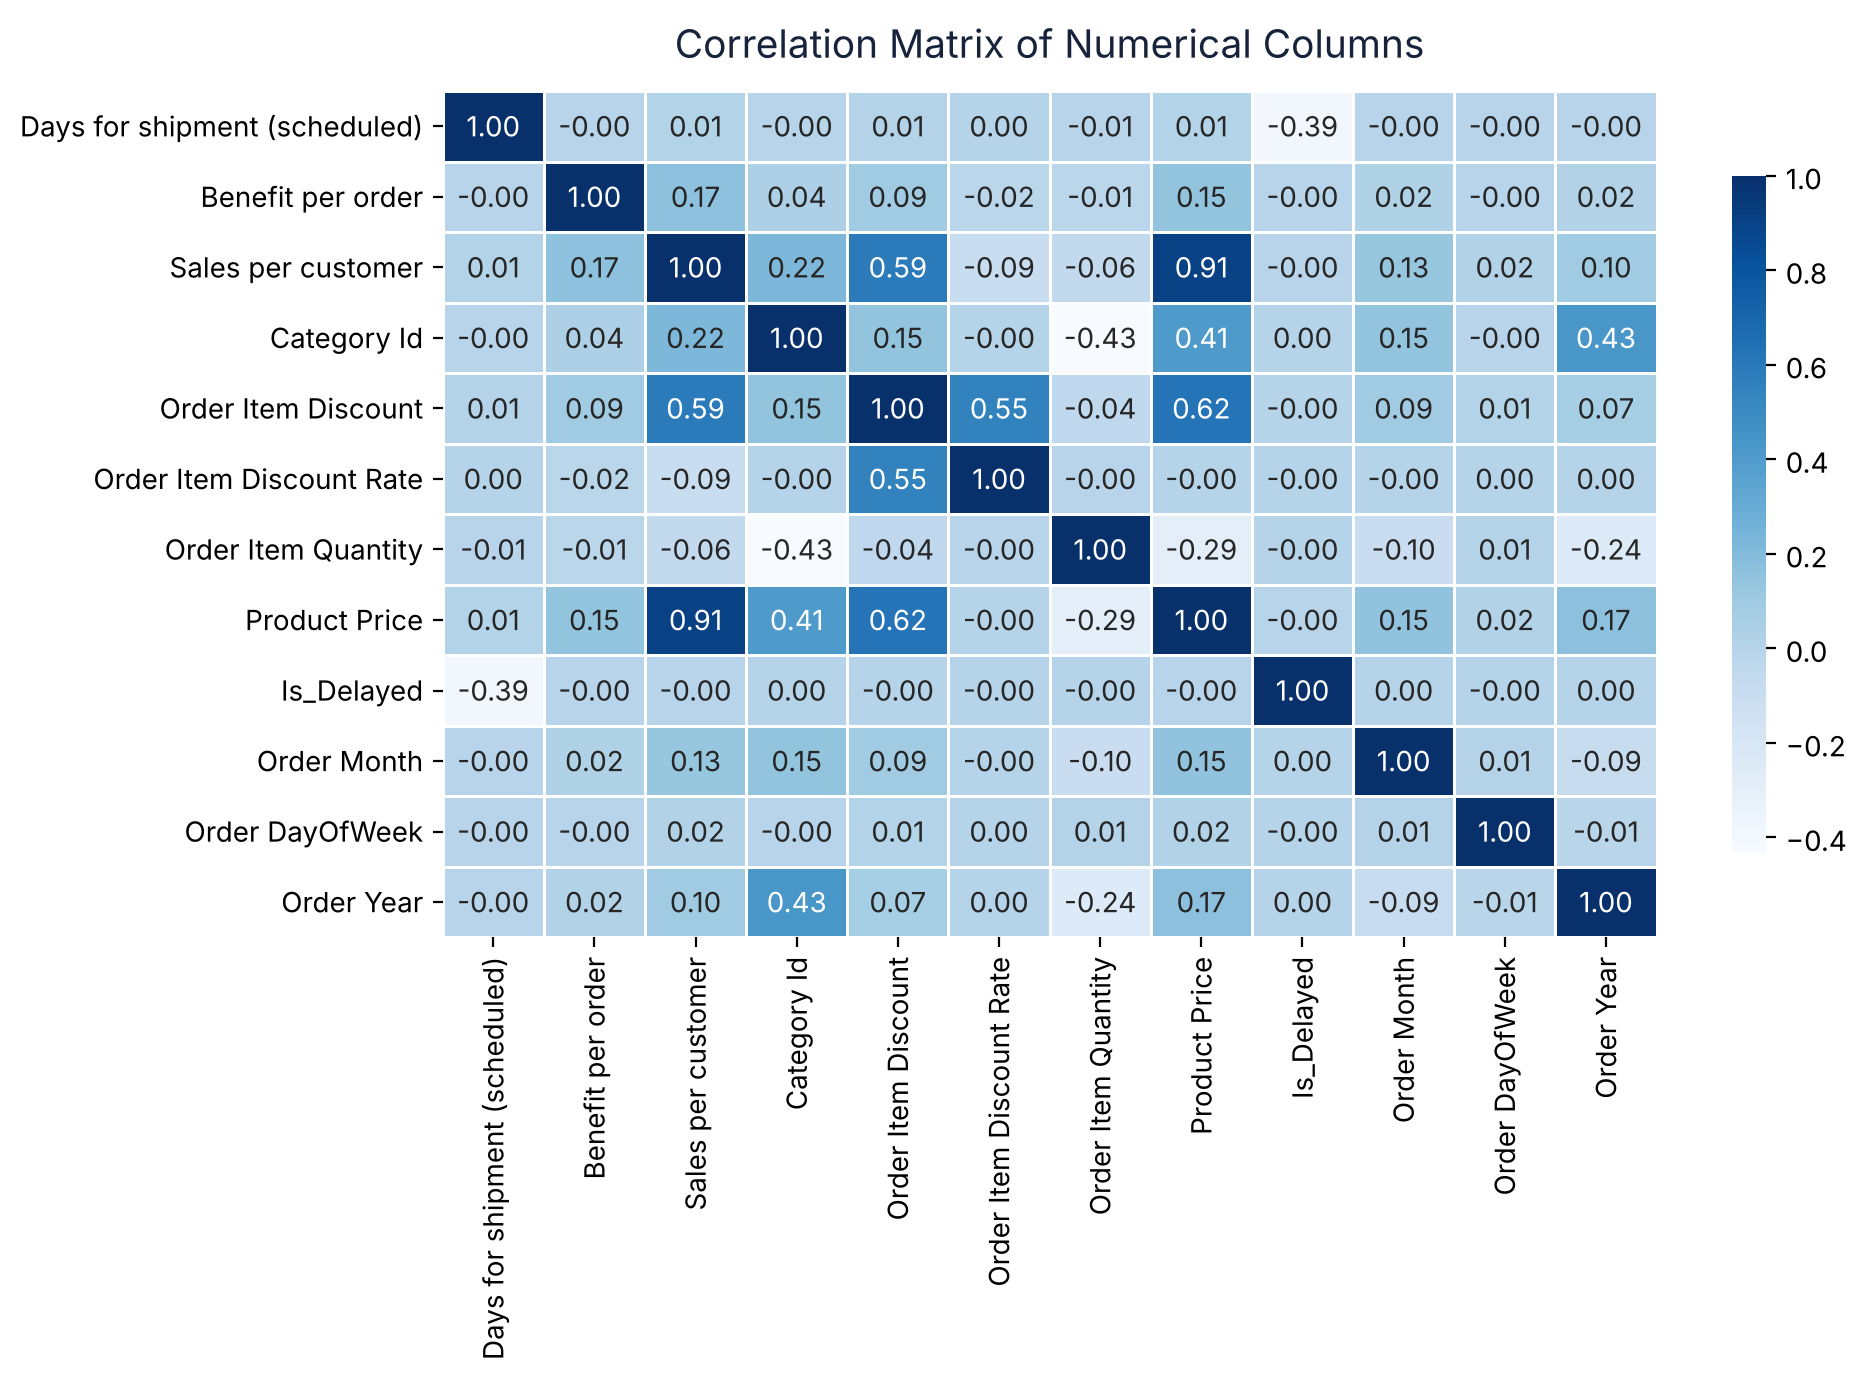

In [7]:
# Quick correlation check of the numerical columns (identifier excluded)
corr_cols = [c for c in numeric_cols if c not in ["Order Id"]]
plt.figure(figsize=(10, 7))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="Blues", linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlation Matrix of Numerical Columns", fontsize=14, color=NAVY, pad=12)
plt.tight_layout()
plt.show()

In [8]:
# 5) Features and target for machine learning
TARGET = "Is_Delayed"

NUM_FEATURES = ["Days for shipment (scheduled)", "Benefit per order", "Sales per customer", "Category Id",
                "Order Item Discount", "Order Item Discount Rate", "Order Item Quantity", "Product Price",
                "Order Month", "Order DayOfWeek", "Order Year"]
LOW_CARD_FEATURES = ["Type", "Customer Segment", "Customer Country", "Market", "Order Region", "Shipping Mode"]   # one-hot encoded
HIGH_CARD_FEATURES = ["Category Name", "Customer State", "Order Country", "Order City"]                           # ordinal encoded
FEATURES = NUM_FEATURES + LOW_CARD_FEATURES + HIGH_CARD_FEATURES

X = df[FEATURES].copy()
y = df[TARGET].copy()

assert "Order Id" not in FEATURES and TARGET not in FEATURES      # leakage guard

print(f"Features used : {len(FEATURES)}  (numeric {len(NUM_FEATURES)}, low-cardinality categorical {len(LOW_CARD_FEATURES)}, high-cardinality categorical {len(HIGH_CARD_FEATURES)})")
print("Excluded      : Order Id (identifier), Is_Delayed (target), helper columns created in this notebook")
print("\nTarget distribution:")
display(pd.DataFrame({"Orders": y.value_counts().sort_index(), "Share (%)": y.value_counts(normalize=True).sort_index() * 100})
        .rename(index={0: "0 - Not Delayed", 1: "1 - Delayed"}))

Features used : 21  (numeric 11, low-cardinality categorical 6, high-cardinality categorical 4)
Excluded      : Order Id (identifier), Is_Delayed (target), helper columns created in this notebook

Target distribution:


,Orders,Share (%)
Is_Delayed,,
0 - Not Delayed,28054,42.67
1 - Delayed,37698,57.33


**Preprocessing summary.** The dataset has no missing values and no duplicate records, so no valid record was removed. Text labels were tidied and helper columns were added without changing the original columns. The machine-learning pipeline (Section 10) still contains imputers so that it handles missing values safely if a new file is used. `Order Id` is excluded from the features to prevent leakage, and no field created from the target is used as a feature.

# 4. Executive Overview

This section recreates the first page of the dashboard: headline KPIs, the monthly sales trend, delivery status, shipping mode performance and regional sales contribution.

> **Note on sales:** `Sales per customer` is the only sales measure in the dataset. All "sales" figures below are **sums of this column** over the order records in this file; they are not order counts, and they will not match the item-level `Sales` totals of the original dashboard.

In [9]:
total_orders = df["Order Id"].nunique()
total_sales = df[SALES].sum()
delayed_orders = int((df["Is_Delayed"] == 1).sum())
non_delayed_orders = int((df["Is_Delayed"] == 0).sum())
delay_pct = delayed_orders / total_orders * 100

kpi_cards([
    ("Total Orders", f"{total_orders:,}", "Distinct Order Ids", "📦"),
    ("Total Sales", f"{total_sales:,.0f}", "Sum of 'Sales per customer'", "💰"),
    ("Delayed Orders", f"{delayed_orders:,}", "Is_Delayed = 1", "⚠️"),
    ("Non-Delayed Orders", f"{non_delayed_orders:,}", "Is_Delayed = 0", "✅"),
    ("Delivery Delay %", f"{delay_pct:.1f}%", "Share of all orders", "📉"),
])

In [10]:
# Monthly Sales Trend (area chart)
monthly_sales = df.groupby("Order Period", as_index=False)[SALES].sum()

fig = px.area(monthly_sales, x="Order Period", y=SALES, markers=True, color_discrete_sequence=[BLUE],
              title="Monthly Sales Trend",
              labels={"Order Period": "Order Month", SALES: "Sales (sum of Sales per customer)"})
fig.update_traces(fill="tozeroy", line=dict(width=3), hovertemplate="%{x|%b %Y}<br>Sales: %{y:,.0f}<extra></extra>")
show(fig, 400)

In [11]:
# Delivery Status Distribution (donut)
status_counts = df["Delivery Status"].value_counts().reset_index()
status_counts.columns = ["Status", "Orders"]

fig = px.pie(status_counts, names="Status", values="Orders", hole=0.65, color="Status",
             color_discrete_map=STATUS_COLORS, title="Delivery Status Distribution")
fig.update_traces(textposition="inside", textinfo="percent+label", hovertemplate="%{label}<br>Orders: %{value:,}<extra></extra>")
fig.add_annotation(text=f"<b>{total_orders:,}</b><br>orders", showarrow=False, font=dict(size=15, color=NAVY))
show(fig, 400)

In [12]:
# Shipping Mode Bar Chart
# ALTERNATIVE CHART: the dashboard plotted average ACTUAL shipping days, which is not in this dataset.
# Here the delay rate (share of orders with Is_Delayed = 1) is shown for each shipping mode.
mode_perf = (df.groupby("Shipping Mode")
               .agg(Total_Orders=("Order Id", "nunique"),
                    Delayed_Orders=("Is_Delayed", "sum"),
                    Scheduled_Days=("Days for shipment (scheduled)", "mean"))
               .reset_index())
mode_perf["Delay Rate (%)"] = mode_perf["Delayed_Orders"] / mode_perf["Total_Orders"] * 100
mode_perf = mode_perf.sort_values("Delay Rate (%)")

fig = px.bar(mode_perf, x="Shipping Mode", y="Delay Rate (%)", color="Delay Rate (%)", color_continuous_scale="Blues",
             hover_data={"Total_Orders": ":,", "Delayed_Orders": ":,", "Scheduled_Days": ":.0f"}, text="Delay Rate (%)",
             title="Shipping Mode Performance: Delay Rate (alternative to average actual days)")
fig.update_traces(texttemplate="%{text:.1f}%", textposition="outside")
fig.update_layout(yaxis_range=[0, 115], coloraxis_showscale=False)
show(fig)

In [13]:
# Regional Sales Contribution (top 10 regions)
region_sales = (df.groupby("Order Region", as_index=False)[SALES].sum()
                  .sort_values(SALES, ascending=False).head(10))

fig = px.bar(region_sales, x=SALES, y="Order Region", orientation="h", color=SALES, color_continuous_scale="Blues",
             title="Regional Sales Contribution (Top 10 Regions)",
             labels={SALES: "Sales (sum of Sales per customer)"})
fig.update_layout(yaxis={"categoryorder": "total ascending"}, coloraxis_showscale=False)
show(fig, 420)

### 4.1 Business Intelligence & Insights
The dashboard generated three insight cards and a recommended action. The same rules are used here (delay thresholds of 30% and 15%). The shipping-mode card uses the **highest delay rate**, because average delay days are not available.

In [14]:
top_region = df.groupby("Order Region")[SALES].sum().sort_values(ascending=False)
mode_delay_rate = df.groupby("Shipping Mode")["Is_Delayed"].mean().sort_values(ascending=False) * 100

if delay_pct >= 30:
    health_text, health_color = "High delivery delay", RED
elif delay_pct >= 15:
    health_text, health_color = "Moderate delivery delay", AMBER
else:
    health_text, health_color = "Lower delivery delay", GREEN

kpi_cards([
    ("Top Sales Region", top_region.index[0], f"Sales: {top_region.iloc[0]:,.0f}", "🏆"),
    ("Shipping Delay Alert", mode_delay_rate.index[0], f"Delay rate: {mode_delay_rate.iloc[0]:.1f}% (highest mode)", "⚠️"),
    ("Delivery Health", f"{delay_pct:.1f}%", f"{delayed_orders:,} / {total_orders:,} orders delayed: {health_text}", "📦"),
])

if delay_pct >= 30:
    action = "Delivery delays are high. Review shipping schedules and investigate the shipping modes with the highest delay rates."
elif delay_pct >= 15:
    action = "Delivery performance needs attention. Monitor delayed orders and review regional shipping operations."
else:
    action = "Delivery performance is relatively stable. Continue monitoring shipping efficiency."
display(Markdown(f"**Recommended business action:** {action}"))

**Recommended business action:** Delivery delays are high. Review shipping schedules and investigate the shipping modes with the highest delay rates.

**Executive Overview conclusion.** The KPI cards and insight rules above summarise the whole dataset. The delay percentage, the shipping-mode delay rates and the regional sales ranking are computed directly from the data, so they update automatically if the CSV is replaced.

# 5. Delivery Intelligence

The dashboard page analysed delivery speed and delay patterns. Two of its charts depend on columns that are **not in `ml_training_data.csv`**:

| Original chart | Missing column(s) | Treatment |
|---|---|---|
| Actual vs Scheduled Delivery (grouped bar) | `Days for shipping (real)` | Not reproduced. Actual duration cannot be derived from scheduled duration, so it is not fabricated. Alternative: delayed vs not-delayed orders by shipping mode. |
| Delivery Delay Distribution (histogram) | `Delivery Delay Days` | Not reproduced. Alternative: monthly delay-rate trend. |

In [15]:
avg_scheduled = df["Days for shipment (scheduled)"].mean()

kpi_cards([
    ("Not Delayed Orders", f"{non_delayed_orders:,}", "Unique orders", "✅"),
    ("Delayed Orders", f"{delayed_orders:,}", "Unique orders", "⚠️"),
    ("Delayed Rate", f"{delay_pct:.1f}%", "Share of unique orders", "📉"),
    ("Avg Scheduled Days", f"{avg_scheduled:.2f} days", "Planned delivery duration", "🕒"),
])

In [16]:
# ALTERNATIVE to "Actual vs Scheduled Delivery": delayed vs not-delayed orders per shipping mode
status_mode = (df.groupby(["Shipping Mode", "Delivery Status"]).size().reset_index(name="Orders"))
mode_order = df.groupby("Shipping Mode")["Days for shipment (scheduled)"].mean().sort_values().index.tolist()

fig = px.bar(status_mode, x="Shipping Mode", y="Orders", color="Delivery Status", barmode="group",
             color_discrete_map=STATUS_COLORS, category_orders={"Shipping Mode": mode_order},
             title="Delayed vs Not Delayed Orders by Shipping Mode (alternative to Actual vs Scheduled)",
             text_auto=",")
fig.update_traces(textposition="outside")
show(fig)

In [17]:
# ALTERNATIVE to the delay histogram: monthly delay-rate trend
monthly_delay = (df.groupby("Order Period")
                   .agg(Orders=("Order Id", "nunique"), Delayed=("Is_Delayed", "sum")).reset_index())
monthly_delay["Delay Rate (%)"] = monthly_delay["Delayed"] / monthly_delay["Orders"] * 100

fig = px.line(monthly_delay, x="Order Period", y="Delay Rate (%)", markers=True, color_discrete_sequence=[RED],
              hover_data={"Orders": ":,", "Delayed": ":,"},
              title="Monthly Delivery Delay Rate (alternative to the delay-days histogram)")
fig.update_traces(line_width=3)
fig.add_hline(y=delay_pct, line_dash="dash", line_color=NAVY, annotation_text=f"Overall: {delay_pct:.1f}%")
show(fig)

In [18]:
# Shipping Mode Detailed Performance (table)
shipping_table = (df.groupby("Shipping Mode")
                    .agg(Total_Orders=("Order Id", "nunique"),
                         Scheduled_Days=("Days for shipment (scheduled)", "mean"),
                         Delayed_Orders=("Is_Delayed", "sum"),
                         Avg_Sales_per_Order=(SALES, "mean"))
                    .reset_index())
shipping_table["Delay_Rate_%"] = shipping_table["Delayed_Orders"] / shipping_table["Total_Orders"] * 100
shipping_table = shipping_table.sort_values("Scheduled_Days").round(2)
display(shipping_table.style.hide(axis="index").format({"Total_Orders": "{:,.0f}", "Delayed_Orders": "{:,.0f}"}))

Shipping Mode,Total_Orders,Scheduled_Days,Delayed_Orders,Avg_Sales_per_Order,Delay_Rate_%
Same Day,"3,571",0.000000,"1,727",182.680000,48.360000
First Class,"10,079",1.000000,"10,079",191.050000,100.000000
Second Class,"12,778",2.000000,"10,213",188.550000,79.930000
Standard Class,"39,324",4.000000,"15,679",191.250000,39.870000


In [19]:
worst_mode = shipping_table.sort_values("Delay_Rate_%", ascending=False).iloc[0]
best_mode = shipping_table.sort_values("Delay_Rate_%").iloc[0]
display(Markdown(f'''
### Delivery Performance Summary
- **{delayed_orders:,}** of **{total_orders:,}** orders ({delay_pct:.1f}%) are marked as delayed.
- The highest delay rate is for **{worst_mode['Shipping Mode']}** ({worst_mode['Delay_Rate_%']:.1f}%, scheduled {worst_mode['Scheduled_Days']:.0f} day(s)); the lowest is for **{best_mode['Shipping Mode']}** ({best_mode['Delay_Rate_%']:.1f}%, scheduled {best_mode['Scheduled_Days']:.0f} day(s)).
- **Standard Class** carries the largest order volume ({int(shipping_table.loc[shipping_table['Shipping Mode']=='Standard Class','Total_Orders'].iloc[0]):,} orders), so it contributes most delayed orders in absolute numbers even though its delay rate is not the highest.
- Each shipping mode has one fixed scheduled duration in this data, so "shipping mode" and "scheduled days" carry the same information.
- Actual delivery days and delay days are not available; the size of delays (in days) therefore cannot be measured here.
'''))


### Delivery Performance Summary
- **37,698** of **65,752** orders (57.3%) are marked as delayed.
- The highest delay rate is for **First Class** (100.0%, scheduled 1 day(s)); the lowest is for **Standard Class** (39.9%, scheduled 4 day(s)).
- **Standard Class** carries the largest order volume (39,324 orders), so it contributes most delayed orders in absolute numbers even though its delay rate is not the highest.
- Each shipping mode has one fixed scheduled duration in this data, so "shipping mode" and "scheduled days" carry the same information.
- Actual delivery days and delay days are not available; the size of delays (in days) therefore cannot be measured here.


# 6. Delivery Risk Analysis

The original page used the dataset's `Late_delivery_risk` indicator. In this dataset the equivalent existing label is `Is_Delayed`: **High Risk = 1, Low Risk = 0**. These are recorded values from the dataset, **not predictions of the machine-learning models** in Sections 10-11.

In [20]:
high_risk = int((df["Risk Status"] == "High Risk").sum())
low_risk = int((df["Risk Status"] == "Low Risk").sum())

kpi_cards([
    ("Total Risk Records", f"{len(df):,}", "Unique orders with valid risk data", "📦"),
    ("High-Risk Orders", f"{high_risk:,}", "Is_Delayed = 1", "⚠️"),
    ("Low-Risk Orders", f"{low_risk:,}", "Is_Delayed = 0", "✅"),
    ("High-Risk Rate", f"{high_risk / len(df) * 100:.1f}%", "Share of valid records", "📊"),
])

In [21]:
# Delivery Risk Distribution (donut)
risk_dist = df["Risk Status"].value_counts().reset_index()
risk_dist.columns = ["Risk Status", "Orders"]

fig = px.pie(risk_dist, names="Risk Status", values="Orders", hole=0.6, color="Risk Status",
             color_discrete_map=STATUS_COLORS, title="Delivery Risk Distribution")
fig.update_traces(textposition="inside", textinfo="percent+label", hovertemplate="%{label}<br>Orders: %{value:,}<extra></extra>")
show(fig, 400)

In [22]:
def risk_by(group_col):
    # High-risk order counts and rates for any grouping column
    t = (df.groupby(group_col)
           .agg(Total_Orders=("Order Id", "nunique"), High_Risk_Orders=("Is_Delayed", "sum"))
           .reset_index())
    t["High Risk Rate"] = t["High_Risk_Orders"] / t["Total_Orders"] * 100
    return t

# Risk by Shipping Mode (horizontal bar)
mode_risk = risk_by("Shipping Mode")
fig = px.bar(mode_risk.sort_values("High Risk Rate"), x="High Risk Rate", y="Shipping Mode", orientation="h",
             color="High Risk Rate", color_continuous_scale="Reds", hover_data=["Total_Orders", "High_Risk_Orders"],
             text="High Risk Rate", title="Risk by Shipping Mode",
             labels={"High Risk Rate": "High-Risk Orders (%)"})
fig.update_traces(texttemplate="%{text:.1f}%", textposition="outside")
fig.update_layout(xaxis_range=[0, 115], coloraxis_showscale=False)
show(fig, 380)

In [23]:
# Regional Delivery Risk Comparison
region_risk = risk_by("Order Region").sort_values("High Risk Rate", ascending=False)

fig = px.bar(region_risk, x="Order Region", y="High Risk Rate", color="High Risk Rate", color_continuous_scale="Reds",
             hover_data=["Total_Orders", "High_Risk_Orders"], title="Regional Delivery Risk Comparison",
             labels={"High Risk Rate": "High-Risk Orders (%)"})
fig.add_hline(y=delay_pct, line_dash="dash", line_color=NAVY, annotation_text=f"Overall {delay_pct:.1f}%")
fig.update_layout(xaxis_tickangle=-40, coloraxis_showscale=False)
show(fig, 460)

### 6.1 Delayed vs Non-Delayed Order Comparison
The dashboard compared recorded risk with actual delay days (not available here). Instead, the table and chart below compare the **average characteristics** of delayed and non-delayed orders.

In [24]:
compare_cols = [SALES, "Benefit per order", "Product Price", "Order Item Quantity", "Order Item Discount Rate",
                "Days for shipment (scheduled)"]
comparison = df.groupby("Delivery Status")[compare_cols].mean().T
comparison["Difference (Delayed - Not Delayed)"] = comparison["Delayed"] - comparison["Not Delayed"]
display(comparison.round(3))

fig = make_subplots(rows=1, cols=4, subplot_titles=["Sales per customer", "Benefit per order", "Product Price", "Scheduled Days"])
for i, col in enumerate([SALES, "Benefit per order", "Product Price", "Days for shipment (scheduled)"], start=1):
    for status in ["Not Delayed", "Delayed"]:
        fig.add_trace(go.Bar(x=[status], y=[comparison.loc[col, status]], marker_color=STATUS_COLORS[status],
                             name=status, showlegend=(i == 1),
                             text=[f"{comparison.loc[col, status]:.1f}"], textposition="outside"), row=1, col=i)
fig.update_layout(title="Average Characteristics: Delayed vs Not Delayed Orders", barmode="group")
fig.update_yaxes(rangemode="tozero")
show(fig, 400)

Delivery Status,Delayed,Not Delayed,Difference (Delayed - Not Delayed)
Sales per customer,189.86,190.72,-0.85
Benefit per order,22.95,23.36,-0.41
Product Price,154.07,154.59,-0.52
Order Item Quantity,5.84,5.85,-0.01
Order Item Discount Rate,0.10,0.10,-0.00
Days for shipment (scheduled),2.47,3.55,-1.08


In [25]:
worst_region = region_risk.iloc[0]
best_region = region_risk.iloc[-1]
mode_sorted = mode_risk.sort_values("High Risk Rate", ascending=False)
display(Markdown(f'''
### Delivery Risk Summary
- Overall high-risk (delayed) rate: **{high_risk / len(df) * 100:.1f}%**.
- Highest-risk shipping mode: **{mode_sorted.iloc[0]['Shipping Mode']}** ({mode_sorted.iloc[0]['High Risk Rate']:.1f}%); lowest: **{mode_sorted.iloc[-1]['Shipping Mode']}** ({mode_sorted.iloc[-1]['High Risk Rate']:.1f}%).
- Highest-risk region: **{worst_region['Order Region']}** ({worst_region['High Risk Rate']:.1f}%); lowest: **{best_region['Order Region']}** ({best_region['High Risk Rate']:.1f}%).
- These are recorded labels from the dataset. They describe patterns in the data and do not show *why* orders were delayed.
'''))


### Delivery Risk Summary
- Overall high-risk (delayed) rate: **57.3%**.
- Highest-risk shipping mode: **First Class** (100.0%); lowest: **Standard Class** (39.9%).
- Highest-risk region: **Central Africa** (60.6%); lowest: **Canada** (52.8%).
- These are recorded labels from the dataset. They describe patterns in the data and do not show *why* orders were delayed.


# 7. Regional Analytics

Regional order volume, delivery risk and sales are compared. The dashboard's "Average Delivery Delay by Region" used delay days (not available), so **delay rate** is used instead and labelled accordingly.

In [26]:
regional = (df.groupby("Order Region")
              .agg(Total_Orders=("Order Id", "nunique"),
                   Delayed_Orders=("Is_Delayed", "sum"),
                   Sales=(SALES, "sum"),
                   Avg_Sales_per_Order=(SALES, "mean"),
                   Avg_Benefit_per_Order=("Benefit per order", "mean"))
              .reset_index())
regional["Delay_Rate_%"] = regional["Delayed_Orders"] / regional["Total_Orders"] * 100
regional["Order_Share_%"] = regional["Total_Orders"] / regional["Total_Orders"].sum() * 100
print(f"Regions in dataset: {len(regional)}")

Regions in dataset: 23


In [27]:
# 7.1 Regional Order Distribution
fig = px.bar(regional.sort_values("Total_Orders"), x="Total_Orders", y="Order Region", orientation="h",
             color="Total_Orders", color_continuous_scale="Blues", hover_data={"Order_Share_%": ":.1f"},
             title="Regional Order Distribution (number of orders)", labels={"Total_Orders": "Orders"})
fig.update_layout(coloraxis_showscale=False)
show(fig, 560)

In [28]:
# 7.2 Regional Delivery Risk (delay rate; replaces 'Average Delivery Delay by Region')
fig = px.bar(regional.sort_values("Delay_Rate_%"), x="Delay_Rate_%", y="Order Region", orientation="h",
             color="Delay_Rate_%", color_continuous_scale="RdYlGn_r", hover_data=["Total_Orders", "Delayed_Orders"],
             title="Regional Delivery Risk: Delay Rate by Region (replaces average delay days)",
             labels={"Delay_Rate_%": "Delayed Orders (%)"})
fig.add_vline(x=delay_pct, line_dash="dash", line_color=NAVY, annotation_text=f"Overall {delay_pct:.1f}%")
fig.update_layout(coloraxis_showscale=False)
show(fig, 560)

In [29]:
# 7.3 Regional Sales Analysis
fig = px.bar(regional.sort_values("Sales", ascending=False), x="Order Region", y="Sales", color="Sales",
             color_continuous_scale="Blues", title="Regional Sales Performance",
             labels={"Sales": "Sales (sum of Sales per customer)"})
fig.update_layout(xaxis_tickangle=-40, coloraxis_showscale=False)
show(fig, 440)

# 7.4 Regional Performance Comparison (performance matrix)
fig = px.scatter(regional, x="Delay_Rate_%", y="Sales", size="Total_Orders", color="Order Region",
                 hover_name="Order Region", size_max=45,
                 title="Regional Performance Matrix: Delay Rate vs Sales (bubble size = orders)",
                 labels={"Delay_Rate_%": "Delayed Orders (%)", "Sales": "Sales (sum of Sales per customer)"})
show(fig, 500)

In [30]:
# 7.5 Regional Summary Table
regional_summary = regional.sort_values("Sales", ascending=False).round(2).reset_index(drop=True)
display(regional_summary.style.hide(axis="index").format(
    {"Total_Orders": "{:,.0f}", "Delayed_Orders": "{:,.0f}", "Sales": "{:,.0f}"}))

top_orders = regional.sort_values("Total_Orders", ascending=False).iloc[0]
top_sales = regional.sort_values("Sales", ascending=False).iloc[0]
risk_hi = regional.sort_values("Delay_Rate_%", ascending=False).iloc[0]
risk_lo = regional.sort_values("Delay_Rate_%").iloc[0]
display(Markdown(f'''
**Regional conclusion.** Most orders: **{top_orders['Order Region']}** ({top_orders['Total_Orders']:,.0f}, {top_orders['Order_Share_%']:.1f}% of all orders). Highest sales: **{top_sales['Order Region']}** ({top_sales['Sales']:,.0f}).
Delay rates range from **{risk_lo['Delay_Rate_%']:.1f}%** ({risk_lo['Order Region']}) to **{risk_hi['Delay_Rate_%']:.1f}%** ({risk_hi['Order Region']}).
Regions with few orders show less stable rates, so differences between them should be read with care.
'''))

Order Region,Total_Orders,Delayed_Orders,Sales,Avg_Sales_per_Order,Avg_Benefit_per_Order,Delay_Rate_%,Order_Share_%
Western Europe,"10,010","5,842","2,171,414",216.920000,25.530000,58.360000,15.220000
Central America,"9,396","5,394","1,686,576",179.500000,21.810000,57.410000,14.290000
South America,"4,979","2,841","885,714",177.890000,22.260000,57.060000,7.570000
Southeast Asia,"4,356","2,530","820,312",188.320000,24.770000,58.080000,6.620000
Northern Europe,"3,716","2,087","818,220",220.190000,26.970000,56.160000,5.650000
Oceania,"4,362","2,481","787,393",180.510000,20.340000,56.880000,6.630000
Southern Europe,"3,543","1,984","765,830",216.150000,26.440000,56.000000,5.390000
Eastern Asia,"3,318","1,900","636,109",191.710000,22.120000,57.260000,5.050000
South Asia,"3,335","1,939","621,343",186.310000,22.590000,58.140000,5.070000
Caribbean,"2,806","1,569","502,750",179.170000,22.100000,55.920000,4.270000



**Regional conclusion.** Most orders: **Western Europe** (10,010, 15.2% of all orders). Highest sales: **Western Europe** (2,171,414).
Delay rates range from **52.8%** (Canada) to **60.6%** (Central Africa).
Regions with few orders show less stable rates, so differences between them should be read with care.


# 8. Revenue Analytics

This section separates **monetary values** (`Sales per customer`, summed) from **volume measures** (order counts and item quantities), which are always labelled as counts.

In [31]:
total_items = df["Order Item Quantity"].sum()
kpi_cards([
    ("Total Sales", f"{total_sales:,.0f}", "Sum of 'Sales per customer' (money)", "💰"),
    ("Total Item Quantity", f"{total_items:,.0f}", "Units across order records (volume)", "📦"),
    ("Avg Sales per Order", f"{df[SALES].mean():,.2f}", "Average 'Sales per customer' per order record", "📈"),
])

In [32]:
# 8.1 Monthly Revenue Trend
fig = px.line(monthly_sales, x="Order Period", y=SALES, markers=True, color_discrete_sequence=[BLUE],
              title="Monthly Revenue Trend",
              labels={"Order Period": "Order Month", SALES: "Sales (sum of Sales per customer)"})
fig.update_traces(line_width=3, hovertemplate="%{x|%b %Y}<br>Sales: %{y:,.0f}<extra></extra>")
show(fig, 400)

In [33]:
# 8.2 Sales by Market (donut)  +  Market Sales Comparison (bar)
market_sales = df.groupby("Market")[SALES].sum().reset_index().sort_values(SALES, ascending=False)

fig = px.pie(market_sales, names="Market", values=SALES, hole=0.55, title="Sales by Market (sum of Sales per customer)")
fig.update_traces(textinfo="percent+label", hovertemplate="%{label}<br>Sales: %{value:,.0f}<extra></extra>")
show(fig, 420)

fig = px.bar(market_sales, x="Market", y=SALES, color=SALES, color_continuous_scale="Blues", text_auto=".3s",
             title="Market Sales Comparison", labels={SALES: "Sales (sum of Sales per customer)"})
fig.update_layout(coloraxis_showscale=False)
show(fig, 400)

In [34]:
# 8.3 Market-wise Order Distribution (COUNT of orders, not sales)
market_orders = (df.groupby("Market")
                   .agg(Orders=("Order Id", "nunique"), Delayed=("Is_Delayed", "sum"))
                   .reset_index())
market_orders["Order Share (%)"] = market_orders["Orders"] / market_orders["Orders"].sum() * 100
market_orders["Delay Rate (%)"] = market_orders["Delayed"] / market_orders["Orders"] * 100
market_orders = market_orders.sort_values("Orders", ascending=False)

fig = px.bar(market_orders, x="Market", y="Orders", color="Delay Rate (%)", color_continuous_scale="Reds",
             hover_data={"Order Share (%)": ":.1f"}, text_auto=",",
             title="Market-wise Order Distribution (order counts; colour = delay rate)")
show(fig, 400)

In [35]:
# 8.4 Customer Segment Analysis
segment = (df.groupby("Customer Segment")
             .agg(Orders=("Order Id", "nunique"), Sales=(SALES, "sum"),
                  Avg_Sales_per_Order=(SALES, "mean"), Delayed=("Is_Delayed", "sum"))
             .reset_index())
segment["Delay Rate (%)"] = segment["Delayed"] / segment["Orders"] * 100
segment = segment.sort_values("Sales", ascending=False)

fig = make_subplots(rows=1, cols=3, subplot_titles=["Orders (count)", "Sales (sum of Sales per customer)", "Delay Rate (%)"])
fig.add_trace(go.Bar(x=segment["Customer Segment"], y=segment["Orders"], marker_color=BLUE, name="Orders",
                     text=segment["Orders"], texttemplate="%{text:,}", textposition="outside"), row=1, col=1)
fig.add_trace(go.Bar(x=segment["Customer Segment"], y=segment["Sales"], marker_color=GREEN, name="Sales",
                     text=segment["Sales"], texttemplate="%{text:,.0f}", textposition="outside"), row=1, col=2)
fig.add_trace(go.Bar(x=segment["Customer Segment"], y=segment["Delay Rate (%)"], marker_color=RED, name="Delay Rate",
                     text=segment["Delay Rate (%)"], texttemplate="%{text:.1f}%", textposition="outside"), row=1, col=3)
fig.update_layout(title="Customer Segment Analysis", showlegend=False)
fig.update_yaxes(rangemode="tozero")
show(fig, 420)
display(segment.round(2).style.hide(axis="index").format({"Orders": "{:,.0f}", "Sales": "{:,.0f}", "Delayed": "{:,.0f}"}))

Customer Segment,Orders,Sales,Avg_Sales_per_Order,Delayed,Delay Rate (%)
Consumer,"34,119","6,510,994",190.830000,"19,542",57.280000
Corporate,"19,856","3,787,314",190.740000,"11,359",57.210000
Home Office,"11,777","2,209,572",187.620000,"6,797",57.710000


In [36]:
top_market = market_sales.iloc[0]
top_seg = segment.iloc[0]
display(Markdown(f'''
**Revenue conclusion.** Sales by market and over time use the monetary column `Sales per customer`; order distribution uses order counts.
**{top_market['Market']}** is the largest market by sales ({top_market[SALES] / total_sales * 100:.1f}% of total) and **{top_seg['Customer Segment']}** is the largest customer segment by sales ({top_seg['Sales'] / total_sales * 100:.1f}%).
Data for {int(df.loc[df['Order Year'] == df['Order Year'].max(), 'Order Month'].nunique())} month(s) of {int(df['Order Year'].max())} only are included, so the last part of the trend covers a shorter period than the earlier years.
'''))


**Revenue conclusion.** Sales by market and over time use the monetary column `Sales per customer`; order distribution uses order counts.
**Europe** is the largest market by sales (31.9% of total) and **Consumer** is the largest customer segment by sales (52.1%).
Data for 1 month(s) of 2018 only are included, so the last part of the trend covers a shorter period than the earlier years.


# 9. Product Analytics

Only product information present in the file is used: category name, product price, quantity and sales. No product names, inventory or supplier values are created.

In [37]:
category = (df.groupby("Category Name")
              .agg(Orders=("Order Id", "nunique"),
                   Total_Sales=(SALES, "sum"),
                   Total_Quantity=("Order Item Quantity", "sum"),
                   Average_Product_Price=("Product Price", "mean"),
                   Delayed=("Is_Delayed", "sum"))
              .reset_index())
category["Delay_Rate_%"] = category["Delayed"] / category["Orders"] * 100
category = category.sort_values("Total_Sales", ascending=False).reset_index(drop=True)
print(f"Product categories: {len(category)}")

Product categories: 50


In [38]:
# 9.1 Top 15 Product Categories by Sales
top15 = category.head(15)
fig = px.bar(top15.sort_values("Total_Sales"), x="Total_Sales", y="Category Name", orientation="h",
             color="Total_Sales", color_continuous_scale="Blues", title="Top 15 Product Categories by Sales",
             labels={"Total_Sales": "Sales (sum of Sales per customer)"})
fig.update_layout(coloraxis_showscale=False)
show(fig, 520)

In [39]:
# 9.2 Product Category Demand Treemap (size = quantity, colour = sales)
fig = px.treemap(category.head(20), path=["Category Name"], values="Total_Quantity", color="Total_Sales",
                 color_continuous_scale="Blues", title="Category Demand Distribution (top 20 categories; size = quantity, colour = sales)",
                 hover_data={"Total_Sales": ":,.0f", "Total_Quantity": ":,"})
fig.update_traces(textinfo="label+value")
show(fig, 520)

In [40]:
# 9.3 Product Price Analysis
fig = px.histogram(df, x="Product Price", nbins=40, color_discrete_sequence=[BLUE],
                   title="Product Price Distribution", labels={"Product Price": "Product Price"})
fig.update_layout(yaxis_title="Number of orders", bargap=0.05)
show(fig, 380)

price_top = category.head(15).sort_values("Average_Product_Price")
fig = px.bar(price_top, x="Average_Product_Price", y="Category Name", orientation="h", color="Average_Product_Price",
             color_continuous_scale="Blues", title="Average Product Price: Top 15 Categories by Sales",
             labels={"Average_Product_Price": "Average Product Price"})
fig.update_layout(coloraxis_showscale=False)
show(fig, 500)

In [41]:
# 9.4 Order Item Quantity Analysis
qty = df["Order Item Quantity"].value_counts().sort_index().reset_index()
qty.columns = ["Quantity", "Orders"]
fig = px.bar(qty, x="Quantity", y="Orders", color_discrete_sequence=[BLUE], text_auto=",",
             title="Order Item Quantity Distribution (orders per quantity value)")
fig.update_layout(xaxis=dict(dtick=1))
show(fig, 400)
print(f"Average quantity per order record: {df['Order Item Quantity'].mean():.2f}  |  Median: {df['Order Item Quantity'].median():.0f}")

Average quantity per order record: 5.84  |  Median: 5


In [42]:
# 9.5 Product Category Summary
display(category.drop(columns="Delayed").round(2).style.hide(axis="index").format(
    {"Orders": "{:,.0f}", "Total_Sales": "{:,.0f}", "Total_Quantity": "{:,.0f}"}))

top_cat = category.iloc[0]
top_qty = category.sort_values("Total_Quantity", ascending=False).iloc[0]
cat_risk = category[category["Orders"] >= 500].sort_values("Delay_Rate_%", ascending=False).iloc[0]
_cr = category[category["Orders"] >= 500]["Delay_Rate_%"]
cat_span = _cr.max() - _cr.min()
mode_span = mode_risk["High Risk Rate"].max() - mode_risk["High Risk Rate"].min()
display(Markdown(f'''
**Product conclusion.** Highest sales: **{top_cat['Category Name']}** ({top_cat['Total_Sales']:,.0f}, {top_cat['Total_Sales'] / total_sales * 100:.1f}% of total). Highest quantity: **{top_qty['Category Name']}** ({top_qty['Total_Quantity']:,.0f} units).
Among categories with at least 500 orders, **{cat_risk['Category Name']}** has the highest delay rate ({cat_risk['Delay_Rate_%']:.1f}%).
Delay rates across these categories span {cat_span:.1f} percentage points, compared with {mode_span:.1f} points across shipping modes (Section 6).
'''))

Category Name,Orders,Total_Sales,Total_Quantity,Average_Product_Price,Delay_Rate_%
Men's Footwear,"11,954","1,911,348","75,016",134.020000,58.930000
Water Sports,"7,207","1,303,567","42,490",163.350000,56.540000
Cleats,"7,346","1,246,293","51,958",97.090000,56.060000
Fishing,"3,714","1,051,703","18,367",276.550000,59.180000
Camping & Hiking,"4,303","999,108","25,542",209.020000,58.540000
Cardio Equipment,"4,204","884,409","30,277",114.090000,56.990000
Women's Apparel,"5,302","851,884","36,797",92.830000,55.130000
Indoor/Outdoor Games,"4,633","744,721","32,241",94.800000,56.550000
Computers,442,"595,395",442,1500.000000,52.710000
Shop By Sport,"2,779","407,174","18,980",87.070000,55.310000



**Product conclusion.** Highest sales: **Men's Footwear** (1,911,348, 15.3% of total). Highest quantity: **Men's Footwear** (75,016 units).
Among categories with at least 500 orders, **Cameras** has the highest delay rate (62.0%).
Delay rates across these categories span 6.9 percentage points, compared with 60.1 points across shipping modes (Section 6).


# 10. Machine Learning: Random Forest

**Task:** binary classification of `Is_Delayed` (1 = delayed, 0 = not delayed) from order attributes.

**Design choices**
- **Features:** the 21 order attributes defined in Section 3. `Order Id` and the target are excluded to prevent leakage, and no column derived from the target is used.
- **Preprocessing (inside a pipeline, fitted on training data only):** numeric columns are median-imputed; low-cardinality categorical columns are one-hot encoded; high-cardinality columns (category, state, country, city) are ordinal-encoded; unseen categories are handled safely.
- **Split:** 80% training / 20% testing, **stratified** on `Is_Delayed`, fixed random seed. The same split is used for XGBoost in Section 11.
- **Model:** `RandomForestClassifier`.

In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(f"Training set: {X_train.shape[0]:,} rows | Test set: {X_test.shape[0]:,} rows")
print(f"Delayed share  train: {y_train.mean() * 100:.2f}%  |  test: {y_test.mean() * 100:.2f}%  (stratified)")


def make_preprocessor():
    # Fresh preprocessing object for every model (fitted only on the training data inside the pipeline)
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), NUM_FEATURES),
        ("low", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), LOW_CARD_FEATURES),
        ("high", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                           ("ord", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))]), HIGH_CARD_FEATURES),
    ])


def evaluate_model(name, pipeline):
    # Train on the training split, evaluate on the test split, return all results
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]
    metrics = {
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
    }
    return metrics, y_pred, y_prob


def metric_cards(m):
    kpi_cards([("Accuracy", f"{m['Accuracy']:.4f}", "Correct predictions", "🎯"),
               ("Precision", f"{m['Precision']:.4f}", "Of predicted delayed, truly delayed", "🔎"),
               ("Recall", f"{m['Recall']:.4f}", "Of truly delayed, found", "📡"),
               ("F1-score", f"{m['F1-score']:.4f}", "Balance of precision & recall", "⚖️"),
               ("ROC-AUC", f"{m['ROC-AUC']:.4f}", "Ranking quality", "📈")])


def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    labels = ["Not Delayed", "Delayed"]
    fig = px.imshow(cm, x=[f"Predicted {l}" for l in labels], y=[f"Actual {l}" for l in labels],
                    text_auto=",", color_continuous_scale="Blues", title=title)
    fig.update_layout(coloraxis_showscale=False)
    fig.update_xaxes(side="bottom")
    show(fig, 420)

Training set: 52,601 rows | Test set: 13,151 rows
Delayed share  train: 57.33%  |  test: 57.33%  (stratified)


In [44]:
rf_pipeline = Pipeline([
    ("prep", make_preprocessor()),
    ("model", RandomForestClassifier(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE)),
])

rf_metrics, rf_pred, rf_prob = evaluate_model("Random Forest", rf_pipeline)
metric_cards(rf_metrics)

In [45]:
plot_confusion(y_test, rf_pred, "Random Forest: Confusion Matrix (test set)")
print("Classification report (Random Forest):\n")
print(classification_report(y_test, rf_pred, target_names=["Not Delayed", "Delayed"], digits=4))

Classification report (Random Forest):

              precision    recall  f1-score   support

 Not Delayed     0.5966    0.8401    0.6977      5611
     Delayed     0.8291    0.5772    0.6806      7540

    accuracy                         0.6894     13151
   macro avg     0.7128    0.7087    0.6891     13151
weighted avg     0.7299    0.6894    0.6879     13151



In [46]:
fpr, tpr, _ = roc_curve(y_test, rf_prob)
fig = go.Figure()
fig.add_trace(go.Scatter(x=fpr, y=tpr, mode="lines", line=dict(color=BLUE, width=3),
                         name=f"Random Forest (AUC = {rf_metrics['ROC-AUC']:.4f})"))
fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode="lines", line=dict(color="#98A2B3", dash="dash"), name="Random guess"))
fig.update_layout(title="Random Forest: ROC Curve (test set)", xaxis_title="False Positive Rate", yaxis_title="True Positive Rate")
show(fig, 440)

**Random Forest interpretation.** Accuracy is the share of all test orders classified correctly. Precision tells how many orders predicted as delayed were really delayed, and recall tells how many of the truly delayed orders were found. The confusion matrix shows the exact counts of each outcome. Results are computed on the held-out 20% test set that the model never saw during training. Whether these scores are *good* should be judged against the simple baselines shown in Section 12.

# 11. Machine Learning: XGBoost

XGBoost is a gradient-boosting algorithm that builds trees one after another, each correcting the errors of the previous ones. To keep the comparison fair, it uses **the same features, the same preprocessing and the same train-test split** as the Random Forest.

In [47]:
xgb_pipeline = Pipeline([
    ("prep", make_preprocessor()),
    ("model", XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                            eval_metric="logloss", n_jobs=-1, random_state=RANDOM_STATE)),
])

xgb_metrics, xgb_pred, xgb_prob = evaluate_model("XGBoost", xgb_pipeline)
metric_cards(xgb_metrics)

In [48]:
plot_confusion(y_test, xgb_pred, "XGBoost: Confusion Matrix (test set)")
print("Classification report (XGBoost):\n")
print(classification_report(y_test, xgb_pred, target_names=["Not Delayed", "Delayed"], digits=4))

Classification report (XGBoost):

              precision    recall  f1-score   support

 Not Delayed     0.5976    0.7920    0.6812      5611
     Delayed     0.7958    0.6031    0.6861      7540

    accuracy                         0.6837     13151
   macro avg     0.6967    0.6975    0.6837     13151
weighted avg     0.7112    0.6837    0.6840     13151



In [49]:
# Feature importance (XGBoost, top 15 encoded features)
feature_names = [n.split("__", 1)[1] for n in xgb_pipeline.named_steps["prep"].get_feature_names_out()]
xgb_importance = (pd.DataFrame({"Feature": feature_names,
                                "Importance": xgb_pipeline.named_steps["model"].feature_importances_})
                    .sort_values("Importance", ascending=False).reset_index(drop=True))

fig = px.bar(xgb_importance.head(15).sort_values("Importance"), x="Importance", y="Feature", orientation="h",
             color="Importance", color_continuous_scale="Blues", title="XGBoost: Top 15 Feature Importances")
fig.update_layout(coloraxis_showscale=False)
show(fig, 500)

# 12. Model Comparison

Both models were trained on the same data and evaluated on the same test set. Two simple reference points are added so the scores can be judged in context:
- **Majority-class baseline:** always predicts the most common class.
- **Shipping-mode rule:** for each shipping mode, predicts the class that was most common in the training data (no machine learning).

In [50]:
comparison_df = pd.DataFrame([rf_metrics, xgb_metrics]).set_index("Algorithm")
display(comparison_df.style.format("{:.4f}")
        .highlight_max(axis=0, color="#CDEFE0")
        .set_caption("Model comparison on the stratified test set (best value per metric highlighted)"))

# Reference baselines
majority_class = int(y_train.mode()[0])
baseline_acc = accuracy_score(y_test, np.full(len(y_test), majority_class))
mode_rule = (pd.concat([X_train["Shipping Mode"], y_train], axis=1).groupby("Shipping Mode")[TARGET]
               .agg(lambda s: int(s.mean() >= 0.5)))
rule_pred = X_test["Shipping Mode"].map(mode_rule).fillna(majority_class).astype(int)
rule_acc = accuracy_score(y_test, rule_pred)

display(Markdown(f"**Reference accuracies:** majority-class baseline = **{baseline_acc:.4f}**; shipping-mode rule = **{rule_acc:.4f}**."))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Algorithm,,,,,
Random Forest,0.6894,0.8291,0.5772,0.6806,0.7394
XGBoost,0.6837,0.7958,0.6031,0.6861,0.7364


**Reference accuracies:** majority-class baseline = **0.5733**; shipping-mode rule = **0.6953**.

In [51]:
# Grouped bar chart of all metrics
metrics_long = comparison_df.reset_index().melt(id_vars="Algorithm", var_name="Metric", value_name="Score")
fig = px.bar(metrics_long, x="Metric", y="Score", color="Algorithm", barmode="group", text_auto=".3f",
             color_discrete_map={"Random Forest": BLUE, "XGBoost": AMBER}, title="Random Forest vs XGBoost: Evaluation Metrics")
fig.update_traces(textposition="outside")
fig.update_layout(yaxis_range=[0, 1.1])
show(fig, 440)

# ROC curves on one chart
fig = go.Figure()
for name, prob, color in [("Random Forest", rf_prob, BLUE), ("XGBoost", xgb_prob, AMBER)]:
    f, t, _ = roc_curve(y_test, prob)
    fig.add_trace(go.Scatter(x=f, y=t, mode="lines", line=dict(width=3, color=color),
                             name=f"{name} (AUC = {roc_auc_score(y_test, prob):.4f})"))
fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode="lines", line=dict(color="#98A2B3", dash="dash"), name="Random guess"))
fig.update_layout(title="ROC Curves: Random Forest vs XGBoost", xaxis_title="False Positive Rate", yaxis_title="True Positive Rate")
show(fig, 460)

In [52]:
best_f1 = comparison_df["F1-score"].idxmax()
best_auc = comparison_df["ROC-AUC"].idxmax()
gap_acc = abs(rf_metrics["Accuracy"] - xgb_metrics["Accuracy"])
best_acc = max(rf_metrics["Accuracy"], xgb_metrics["Accuracy"])
lift_text = "above" if best_acc > max(baseline_acc, rule_acc) else "not above"

display(Markdown(f'''
### Explanation of results
- **{best_f1}** has the higher F1-score and **{best_auc}** has the higher ROC-AUC. The accuracy difference between the two models is **{gap_acc:.4f}**.
- The best model accuracy ({best_acc:.4f}) is **{lift_text}** the simple references (majority class {baseline_acc:.4f}; shipping-mode rule {rule_acc:.4f}).
- A larger gap between the models and the shipping-mode rule means the other order attributes add useful information; a small gap means shipping mode alone explains most of what the models learn.
- The models are evaluated on one fixed random split. Small differences between the models may not be meaningful without repeated validation.
'''))


### Explanation of results
- **XGBoost** has the higher F1-score and **Random Forest** has the higher ROC-AUC. The accuracy difference between the two models is **0.0057**.
- The best model accuracy (0.6894) is **not above** the simple references (majority class 0.5733; shipping-mode rule 0.6953).
- A larger gap between the models and the shipping-mode rule means the other order attributes add useful information; a small gap means shipping mode alone explains most of what the models learn.
- The models are evaluated on one fixed random split. Small differences between the models may not be meaningful without repeated validation.


# 13. Feature Importance Analysis

Feature importance shows how much each input was used by the trained model to separate delayed from non-delayed orders. One-hot encoded features are listed separately (for example `Shipping Mode_First Class`) and then combined back into the original column for an easier overview.

> Importance measures **association used by the model, not causation**. A high-importance feature is useful for prediction but does not prove that it *causes* delays.

In [53]:
rf_names = [n.split("__", 1)[1] for n in rf_pipeline.named_steps["prep"].get_feature_names_out()]
rf_importance = (pd.DataFrame({"Feature": rf_names, "Importance": rf_pipeline.named_steps["model"].feature_importances_})
                   .sort_values("Importance", ascending=False).reset_index(drop=True))


def original_column(encoded_name):
    # Map an encoded feature name back to its original column
    for col in LOW_CARD_FEATURES:
        if encoded_name.startswith(col + "_"):
            return col
    return encoded_name


fig = make_subplots(rows=1, cols=2, subplot_titles=["Random Forest: Top 15 Features", "XGBoost: Top 15 Features"],
                    horizontal_spacing=0.28)
for col_idx, (imp, color) in enumerate([(rf_importance, BLUE), (xgb_importance, AMBER)], start=1):
    top = imp.head(15).sort_values("Importance")
    fig.add_trace(go.Bar(x=top["Importance"], y=top["Feature"], orientation="h", marker_color=color,
                         hovertemplate="%{y}<br>Importance: %{x:.4f}<extra></extra>", showlegend=False), row=1, col=col_idx)
fig.update_layout(title="Most Important Encoded Features")
fig.update_xaxes(title_text="Importance", showgrid=True, gridcolor="#E9EDF4")
show(fig, 560)

In [54]:
# Importance combined per ORIGINAL column (one-hot columns summed)
def by_original(imp):
    out = imp.copy()
    out["Original Feature"] = out["Feature"].map(original_column)
    return out.groupby("Original Feature")["Importance"].sum().sort_values(ascending=False)

combined = pd.DataFrame({"Random Forest": by_original(rf_importance), "XGBoost": by_original(xgb_importance)}).fillna(0)
combined["Average"] = combined.mean(axis=1)
combined = combined.sort_values("Average", ascending=False)
display(combined.head(10).style.format("{:.4f}").set_caption("Top 10 original features (importance summed over encoded columns)"))

plot_df = combined.head(12).reset_index().melt(id_vars="Original Feature", value_vars=["Random Forest", "XGBoost"],
                                               var_name="Model", value_name="Importance")
fig = px.bar(plot_df, x="Importance", y="Original Feature", color="Model", orientation="h", barmode="group",
             color_discrete_map={"Random Forest": BLUE, "XGBoost": AMBER},
             title="Feature Importance by Original Column (top 12)",
             category_orders={"Original Feature": combined.head(12).index.tolist()[::-1]})
show(fig, 560)

,Random Forest,XGBoost,Average
Original Feature,,,
Shipping Mode,0.1789,0.6419,0.4104
Days for shipment (scheduled),0.1095,0.1799,0.1447
Order Region,0.0383,0.0813,0.0598
Benefit per order,0.0633,0.0036,0.0334
Order City,0.0588,0.0037,0.0312
Order Item Discount,0.0584,0.0037,0.0311
Sales per customer,0.0584,0.0037,0.0310
Order Item Discount Rate,0.0519,0.0037,0.0278
Product Price,0.0494,0.0037,0.0265


In [55]:
top_rf = by_original(rf_importance).head(3)
top_xgb = by_original(xgb_importance).head(3)
display(Markdown(f'''
### Interpretation
- Random Forest relies most on: **{', '.join(f'{n} ({v:.3f})' for n, v in top_rf.items())}**.
- XGBoost relies most on: **{', '.join(f'{n} ({v:.3f})' for n, v in top_xgb.items())}**.
- Tree models can place high importance on columns with many distinct values (such as city or price), because these offer many split points. Importance values should therefore be read as a guide, not as proof of impact.
- Because shipping mode and scheduled days describe the same thing in this dataset, their importance is shared between them.
- These results describe what the models learned from the data; they do **not** show that changing a feature would change delivery outcomes.
'''))


### Interpretation
- Random Forest relies most on: **Shipping Mode (0.179), Days for shipment (scheduled) (0.110), Benefit per order (0.063)**.
- XGBoost relies most on: **Shipping Mode (0.642), Days for shipment (scheduled) (0.180), Order Region (0.081)**.
- Tree models can place high importance on columns with many distinct values (such as city or price), because these offer many split points. Importance values should therefore be read as a guide, not as proof of impact.
- Because shipping mode and scheduled days describe the same thing in this dataset, their importance is shared between them.
- These results describe what the models learned from the data; they do **not** show that changing a feature would change delivery outcomes.


# 14. Final Insights and Conclusion

In [56]:
cat_rates = category[category["Orders"] >= 500]["Delay_Rate_%"]
region_rates = regional[regional["Total_Orders"] >= 500]["Delay_Rate_%"]
mode_rates = mode_risk["High Risk Rate"]
best_model = comparison_df["ROC-AUC"].idxmax()
if best_acc > rule_acc:
    model_vs_rule = "Both ML approaches add information beyond the shipping-mode rule on accuracy."
else:
    model_vs_rule = ("On accuracy, neither model exceeds the simple shipping-mode rule, so shipping mode (scheduled lead time) "
                     "explains most of what the models can predict from these attributes; their advantage is mainly in probability ranking (ROC-AUC) and recall/precision balance.")

display(Markdown(f'''
## 14.1 Important Findings from the Dashboard Analysis
- The dataset contains **{total_orders:,} orders** with total sales (sum of `Sales per customer`) of **{total_sales:,.0f}**.
- **{delay_pct:.1f}%** of orders are marked as delayed ({delayed_orders:,} delayed vs {non_delayed_orders:,} not delayed), which is {health_text.lower()} under the dashboard's 30% / 15% rule.

## 14.2 Delivery Performance Observations
- Delay rates differ strongly by shipping mode: from **{mode_rates.min():.1f}%** to **{mode_rates.max():.1f}%** (a spread of {mode_rates.max() - mode_rates.min():.1f} percentage points).
- **{mode_sorted.iloc[0]['Shipping Mode']}** has the highest delay rate; **{mode_sorted.iloc[-1]['Shipping Mode']}** has the lowest.
- Delay length in days could not be analysed because actual delivery days are not in the dataset.

## 14.3 Regional and Market Observations
- Among regions with at least 500 orders, delay rates range from **{region_rates.min():.1f}%** to **{region_rates.max():.1f}%**, a spread of {region_rates.max() - region_rates.min():.1f} points, much narrower than the shipping-mode spread.
- Most orders: **{top_orders['Order Region']}**; highest regional sales: **{top_sales['Order Region']}**; largest market by sales: **{top_market['Market']}**.

## 14.4 Product Category Observations
- Highest sales: **{top_cat['Category Name']}**; highest quantity: **{top_qty['Category Name']}**.
- Among categories with at least 500 orders, delay rates range from **{cat_rates.min():.1f}%** to **{cat_rates.max():.1f}%**, a spread of {cat_rates.max() - cat_rates.min():.1f} points.

## 14.5 Machine Learning Findings
- Random Forest: accuracy **{rf_metrics['Accuracy']:.4f}**, F1 **{rf_metrics['F1-score']:.4f}**, ROC-AUC **{rf_metrics['ROC-AUC']:.4f}**.
- XGBoost: accuracy **{xgb_metrics['Accuracy']:.4f}**, F1 **{xgb_metrics['F1-score']:.4f}**, ROC-AUC **{xgb_metrics['ROC-AUC']:.4f}**.
- **{best_model}** has the higher ROC-AUC. For reference, the shipping-mode rule reaches {rule_acc:.4f} accuracy and the majority-class baseline {baseline_acc:.4f}.
- {model_vs_rule}
- Feature importance is an indication of what the models used, not evidence of cause and effect.
'''))


## 14.1 Important Findings from the Dashboard Analysis
- The dataset contains **65,752 orders** with total sales (sum of `Sales per customer`) of **12,507,880**.
- **57.3%** of orders are marked as delayed (37,698 delayed vs 28,054 not delayed), which is high delivery delay under the dashboard's 30% / 15% rule.

## 14.2 Delivery Performance Observations
- Delay rates differ strongly by shipping mode: from **39.9%** to **100.0%** (a spread of 60.1 percentage points).
- **First Class** has the highest delay rate; **Standard Class** has the lowest.
- Delay length in days could not be analysed because actual delivery days are not in the dataset.

## 14.3 Regional and Market Observations
- Among regions with at least 500 orders, delay rates range from **53.7%** to **60.6%**, a spread of 6.9 points, much narrower than the shipping-mode spread.
- Most orders: **Western Europe**; highest regional sales: **Western Europe**; largest market by sales: **Europe**.

## 14.4 Product Category Observations
- Highest sales: **Men's Footwear**; highest quantity: **Men's Footwear**.
- Among categories with at least 500 orders, delay rates range from **55.1%** to **62.0%**, a spread of 6.9 points.

## 14.5 Machine Learning Findings
- Random Forest: accuracy **0.6894**, F1 **0.6806**, ROC-AUC **0.7394**.
- XGBoost: accuracy **0.6837**, F1 **0.6861**, ROC-AUC **0.7364**.
- **Random Forest** has the higher ROC-AUC. For reference, the shipping-mode rule reaches 0.6953 accuracy and the majority-class baseline 0.5733.
- On accuracy, neither model exceeds the simple shipping-mode rule, so shipping mode (scheduled lead time) explains most of what the models can predict from these attributes; their advantage is mainly in probability ranking (ROC-AUC) and recall/precision balance.
- Feature importance is an indication of what the models used, not evidence of cause and effect.


## 14.6 Project Limitations
- **Reduced dataset:** the 65,752-row, 23-column file is an order-level extract. Item-level `Sales`, exact order dates, actual shipping days and delay days were not available, so some dashboard charts were replaced by clearly labelled alternatives.
- **Sales measure:** `Sales per customer` is used as the sales measure; totals are not identical to the original item-level `Sales` totals.
- **Time resolution:** only month and year are known, and the final year is incomplete.
- **Label definition:** `Is_Delayed` is used as provided; how it was derived is not documented in the file.
- **Redundant features:** shipping mode and scheduled days carry the same information, which limits what the models can learn beyond them.
- **Single split:** results come from one stratified split; cross-validation and hyper-parameter tuning were not performed.
- **Association, not causation:** the analysis and feature importance do not establish causes of delays.

## 14.7 Future Enhancements
- Add actual delivery days and delay days to restore the original delivery-duration charts and to model delay length (regression).
- Use cross-validation and hyper-parameter search (for example `RandomizedSearchCV`) for both models.
- Add explainability tools such as permutation importance or SHAP.
- Use a time-based train-test split to test performance on future orders.
- Add class-threshold tuning to balance missed delays against false alarms.
- Deploy the best model inside the Streamlit dashboard for live risk scoring.

## 14.8 Conclusion
This notebook reproduces the analytical structure of the Streamlit **Supply Chain Intelligence** dashboard, covering executive KPIs, delivery, risk, regional, revenue and product analytics, using only the fields available in `ml_training_data.csv`. Where the original charts needed unavailable data, the limitation is stated and an accurately labelled alternative is shown. Random Forest and XGBoost classifiers were trained on an identical stratified split and compared with standard metrics and simple baselines, providing a transparent basis for understanding and anticipating delivery delays.